# SE4095 SNTP Assignment 1 - Political Blogs Network Analysis

### 1. Imports and Setup
Import required libraries and set the random seed for reproducibility.

In [1]:
import networkx as nx
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_SEED = 42

### 2. Load Raw Graph
Load the raw GML file, rename the GML 'label' attribute to 'blog_url' for readability, and inspect graph properties.

In [2]:
graph = nx.read_gml('../data/raw/polblogs.gml', label='id')

# Rename 'label' node attribute to 'blog_url'
for node, data in graph.nodes(data=True):
    if 'label' in data:
        data['blog_url'] = data.pop('label')

print(f"Is Directed: {nx.is_directed(graph)}")
print(f"Number of nodes: {graph.number_of_nodes()}")
print(f"Number of edges: {graph.number_of_edges()}")
print("\nSample node attributes:")
for i, node in enumerate(list(graph.nodes())[:3]):
    print(f"Node {node}: {graph.nodes[node]}")

Is Directed: True
Number of nodes: 1490
Number of edges: 19090

Sample node attributes:
Node 1: {'value': 0, 'source': 'Blogarama', 'blog_url': '100monkeystyping.com'}
Node 2: {'value': 0, 'source': 'BlogCatalog', 'blog_url': '12thharmonic.com/wordpress'}
Node 3: {'value': 0, 'source': 'Blogarama,BlogCatalog', 'blog_url': '40ozblog.blogspot.com'}


### 3. MultiGraph & Duplicate Edge Check
Check if the graph is a MultiDiGraph, count duplicate edges, and convert to a simple DiGraph by dropping duplicates.

In [3]:
is_multi = isinstance(graph, nx.MultiDiGraph)
print(f"Is MultiDiGraph: {is_multi}")

if is_multi:
    num_duplicates = sum(1 for u, v, k in graph.edges(keys=True) if k > 0)
    print(f"Number of duplicate edges: {num_duplicates}")
    
    simple_graph = nx.DiGraph()
    simple_graph.add_nodes_from(graph.nodes(data=True))
    simple_graph.add_edges_from(graph.edges(data=True))
    
    print("Converted MultiDiGraph to simple DiGraph.")
    print("Rule used: keep single edge, drop duplicates, no weight used.")
    graph = simple_graph
else:
    print("Graph is already a simple graph.")

Is MultiDiGraph: True
Number of duplicate edges: 65
Converted MultiDiGraph to simple DiGraph.
Rule used: keep single edge, drop duplicates, no weight used.


### 4. Self-Loop Removal
Count and remove self-loops from the graph.

In [4]:
num_self_loops = nx.number_of_selfloops(graph)
print(f"Edges before self-loop removal: {graph.number_of_edges()}")
print(f"Number of self-loops: {num_self_loops}")

graph.remove_edges_from(nx.selfloop_edges(graph))
print(f"Edges after self-loop removal: {graph.number_of_edges()}")

Edges before self-loop removal: 19025
Number of self-loops: 3
Edges after self-loop removal: 19022


### 5. Missing Attribute Check
Check for nodes missing the 'value' attribute (political orientation).

In [5]:
missing_value_nodes = [node for node, data in graph.nodes(data=True) if 'value' not in data or data['value'] is None]
print(f"Nodes missing 'value' attribute: {len(missing_value_nodes)}")
if missing_value_nodes:
    print(f"Node IDs missing 'value': {missing_value_nodes}")

Nodes missing 'value' attribute: 0


### 6. Isolates Removal
Identify and remove isolated nodes (degree = 0).

In [6]:
isolates = list(nx.isolates(graph))
print(f"Number of isolates: {len(isolates)}")

graph.remove_nodes_from(isolates)
print("isolates carry no link information and cannot participate in centrality or community detection, so they are removed.")
print(f"Nodes remaining: {graph.number_of_nodes()}")

Number of isolates: 266
isolates carry no link information and cannot participate in centrality or community detection, so they are removed.
Nodes remaining: 1224


### 7. Connected Components
Analyze connectivity and extract the largest weakly connected component for further analysis.

In [7]:
wccs = list(nx.weakly_connected_components(graph))
sccs = list(nx.strongly_connected_components(graph))

print(f"Number of weakly connected components: {len(wccs)}")
print(f"Size of largest weakly connected component: {max(len(c) for c in wccs)}")
print(f"Number of strongly connected components: {len(sccs)}")
print(f"Size of largest strongly connected component: {max(len(c) for c in sccs)}")

largest_wcc_nodes = max(wccs, key=len)
analysis_graph = graph.subgraph(largest_wcc_nodes).copy()

print("\nwe restrict analysis to the largest weakly connected component because centrality and distance-based measures are undefined or misleading across disconnected components; this is analysis_graph used for all remaining stages.")

Number of weakly connected components: 2
Size of largest weakly connected component: 1222
Number of strongly connected components: 422
Size of largest strongly connected component: 793

we restrict analysis to the largest weakly connected component because centrality and distance-based measures are undefined or misleading across disconnected components; this is analysis_graph used for all remaining stages.


### 8. Final Graph Summary
Summarize the final `analysis_graph` properties and its node/edge attributes.

In [8]:
avg_in_degree = sum(dict(analysis_graph.in_degree()).values()) / analysis_graph.number_of_nodes()
avg_out_degree = sum(dict(analysis_graph.out_degree()).values()) / analysis_graph.number_of_nodes()

summary_data = {
    'Metric': ['Nodes', 'Edges', 'Density', 'Weakly Connected Components', 'Strongly Connected Components', 'Average In-Degree', 'Average Out-Degree'],
    'Value': [
        analysis_graph.number_of_nodes(),
        analysis_graph.number_of_edges(),
        nx.density(analysis_graph),
        nx.number_weakly_connected_components(analysis_graph),
        nx.number_strongly_connected_components(analysis_graph),
        avg_in_degree,
        avg_out_degree
    ]
}
summary_df = pd.DataFrame(summary_data)
display(summary_df)

print("\nData Dictionary:")
data_dict = {
    'Attribute Type': ['Node', 'Node', 'Node', 'Edge'],
    'Name': ['id', 'value', 'blog_url', '(No attributes)'],
    'Description': [
        'Integer node identifier',
        'Political orientation (0 or 1). 0=liberal, 1=conservative',
        'Original blog identifier / URL',
        'Unweighted directed hyperlink from source to target blog'
    ]
}
display(pd.DataFrame(data_dict))

,Metric,Value
0,Nodes,1222.000000
1,Edges,19021.000000
2,Density,0.012748
3,Weakly Connected Components,1.000000
4,Strongly Connected Components,420.000000
5,Average In-Degree,15.565466
6,Average Out-Degree,15.565466



Data Dictionary:


,Attribute Type,Name,Description
0,Node,id,Integer node identifier
1,Node,value,"Political orientation (0 or 1). 0=liberal, 1=c..."
2,Node,blog_url,Original blog identifier / URL
3,Edge,(No attributes),Unweighted directed hyperlink from source to t...


### 9. Degree Distribution Plot
Plot in-degree and out-degree distributions of the analysis_graph.

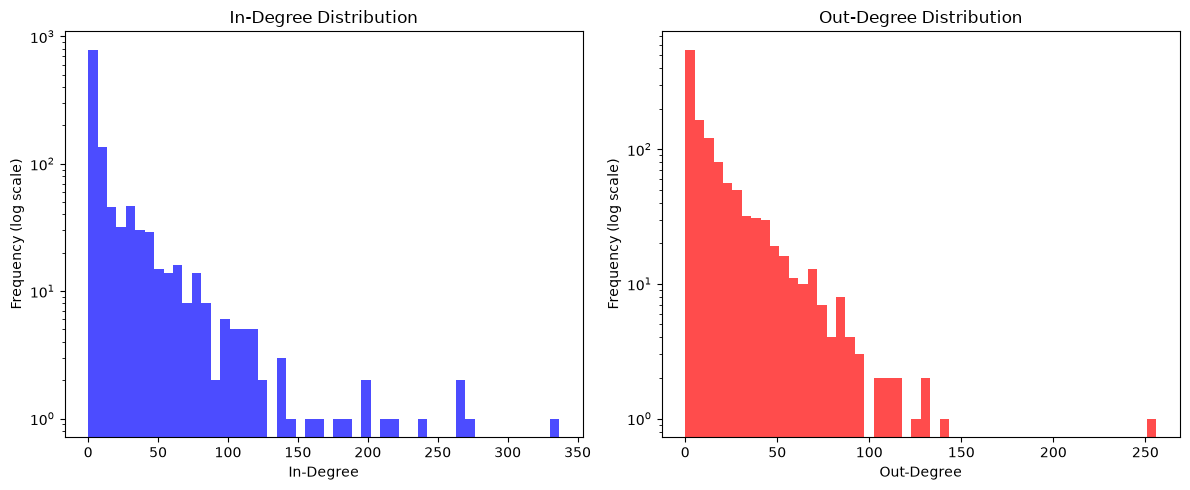

In [9]:
import os
os.makedirs('../reports/figures', exist_ok=True)

in_degrees = [d for n, d in analysis_graph.in_degree()]
out_degrees = [d for n, d in analysis_graph.out_degree()]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(in_degrees, bins=50, color='blue', alpha=0.7)
axes[0].set_yscale('log')
axes[0].set_title('In-Degree Distribution')
axes[0].set_xlabel('In-Degree')
axes[0].set_ylabel('Frequency (log scale)')

axes[1].hist(out_degrees, bins=50, color='red', alpha=0.7)
axes[1].set_yscale('log')
axes[1].set_title('Out-Degree Distribution')
axes[1].set_xlabel('Out-Degree')
axes[1].set_ylabel('Frequency (log scale)')

plt.tight_layout()
plt.savefig('../reports/figures/degree_distribution.png')
plt.show()

### 10. Network Visualization
Visualize a sub-sample of the graph (top 150 nodes by total degree) to observe structure and homophily.

Nodes remaining in visualization subgraph after dropping isolates: 150


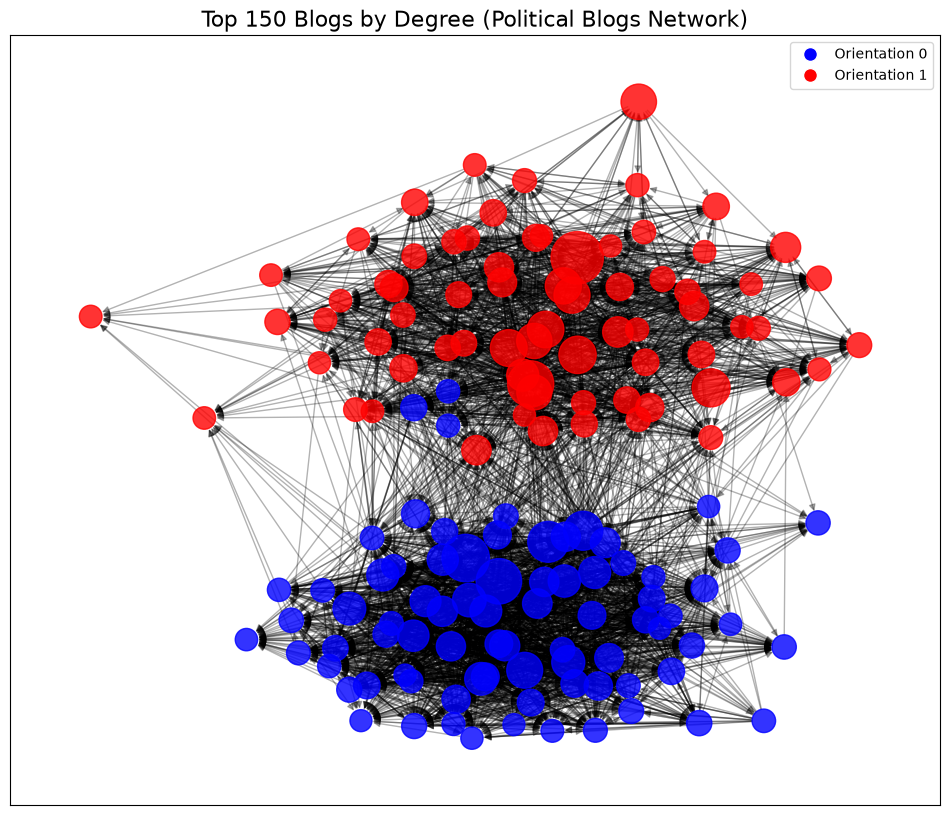

In [10]:
import math
from matplotlib.lines import Line2D

# 1. Take top 150 nodes by total degree
total_degrees = {n: analysis_graph.in_degree(n) + analysis_graph.out_degree(n) for n in analysis_graph.nodes()}
top_150_nodes = sorted(total_degrees, key=total_degrees.get, reverse=True)[:150]

# 2. Build the induced subgraph
vis_graph = analysis_graph.subgraph(top_150_nodes).copy()

# 3. Drop any node with degree 0 WITHIN the subgraph (purely a visualization filter)
isolates_within = list(nx.isolates(vis_graph))
vis_graph.remove_nodes_from(isolates_within)
print(f"Nodes remaining in visualization subgraph after dropping isolates: {vis_graph.number_of_nodes()}")

# 4. Convert to undirected for layout computation
layout_graph = nx.Graph(vis_graph)
# 5. Use spring_layout with adjusted k and iterations
pos = nx.spring_layout(layout_graph, seed=RANDOM_SEED, k=0.5/math.sqrt(vis_graph.number_of_nodes()), iterations=100)

# 6. Color and size nodes
colors = []
for n in vis_graph.nodes():
    val = vis_graph.nodes[n].get('value', -1)
    if val == 0:
        colors.append('blue')
    elif val == 1:
        colors.append('red')
    else:
        colors.append('gray')

node_sizes = [20 + total_degrees[n] * 3 for n in vis_graph.nodes()]

plt.figure(figsize=(12, 10))

# 4b. Draw nodes and edges
nx.draw_networkx_nodes(vis_graph, pos, node_color=colors, node_size=node_sizes, alpha=0.8)
nx.draw_networkx_edges(vis_graph, pos, alpha=0.3, arrows=True, arrowsize=10)

# 7. Add title and legend
plt.title('Top 150 Blogs by Degree (Political Blogs Network)', fontsize=16)

legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Orientation 0', markerfacecolor='blue', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Orientation 1', markerfacecolor='red', markersize=10)
]
plt.legend(handles=legend_elements, loc='best')

# 8. Save and show
plt.savefig('../reports/figures/network_visualization.png', bbox_inches='tight')
plt.show()


### Part A Interpretation

- The in-degree and out-degree distributions are heavy-tailed (visible on the log-scale
  histogram): most blogs receive very few incoming links, while a small number of hub
  blogs receive over 100, with the highest reaching over 300. This power-law-like shape
  indicates that influence in the network is highly concentrated rather than evenly spread.
- The largest weakly connected component contains 1,222 of 1,490 usable nodes (82%),
  showing the political blogosphere is largely one connected discourse space. However,
  422 strongly connected components exist, meaning most blogs are not mutually reachable
  in both directions - reflecting one-directional attention, where smaller blogs link to
  major hubs far more often than hubs link back.
- The top-150 network visualization shows a clear visual separation between the two
  political orientations (red and blue), with only a thin set of edges crossing between
  them. This suggests homophily (linking preferentially within one's own political side)
  is visible in the raw link structure even before any formal community detection.

## Part B: Centrality Selection and Analysis

**Why PageRank?** 
PageRank is designed for directed link networks (like the Web or a blogosphere) where it treats a link as a directed endorsement. It identifies blogs that are seen as authoritative because other important blogs link to them. This is well-suited over plain in-degree because it accounts for the recursive importance of who is linking to a blog, not just the sheer number of inbound links.

**Why Betweenness centrality?** 
Betweenness centrality identifies "broker" blogs that lie on the shortest paths between other blogs. It can reveal blogs that connect otherwise separate ideological clusters (e.g. liberal and conservative sides of the network), which plain degree or PageRank cannot show because those measures focus on popularity/authority rather than structural positioning.

*Question for PageRank: which blogs are seen as most authoritative by the rest of the network?*
*Question for Betweenness: which blogs act as structural bridges connecting different parts of the network?*


### 1. PageRank Computation

In [11]:
import networkx as nx
import pandas as pd
import time

# alpha=0.85 is the standard damping factor from the original PageRank paper,
# representing an 85% probability of following a link vs a 15% random jump.
try:
    pr_scores = nx.pagerank(analysis_graph, alpha=0.85)
    print("PageRank converged successfully (uses power iteration with default max_iter=100 and tol=1e-6).")
except nx.PowerIterationFailedConvergence as e:
    print(f"PageRank failed to converge: {e}")
    pr_scores = {}

pr_data = []
for node, pr in pr_scores.items():
    data = analysis_graph.nodes[node]
    pr_data.append({
        'node_id': node,
        'blog_url': data.get('blog_url', ''),
        'value': data.get('value', -1),
        'pagerank_score': pr
    })

pr_df = pd.DataFrame(pr_data)
pr_df = pr_df.sort_values(by='pagerank_score', ascending=False).reset_index(drop=True)
pr_df['rank'] = pr_df.index + 1

print("\nTop 10 Blogs by PageRank:")
display(pr_df.head(10))

PageRank converged successfully (uses power iteration with default max_iter=100 and tol=1e-6).

Top 10 Blogs by PageRank:


,node_id,blog_url,value,pagerank_score,rank
0,155,dailykos.com,0,0.018896,1
1,55,atrios.blogspot.com,0,0.016029,2
2,1051,instapundit.com,1,0.013318,3
3,855,blogsforbush.com,1,0.013181,4
4,641,talkingpointsmemo.com,0,0.013089,5
5,1153,michellemalkin.com,1,0.011512,6
6,963,drudgereport.com,1,0.011294,7
7,729,washingtonmonthly.com,0,0.011103,8
8,1245,powerlineblog.com,1,0.009426,9
9,798,andrewsullivan.com,1,0.009081,10


### 2. Betweenness Centrality Computation

In [12]:
# normalized=True divides by the number of node pairs so scores are comparable across graphs of different sizes.
# This is an exact computation (not approximated via sampling) since seed is only used internally for tie-breaking 
# in some NetworkX versions.
# Note: betweenness on a directed graph considers directed shortest paths by default, and any node that cannot 
# reach or be reached by another node pair contributes 0 to that pair's betweenness (unreachable pairs are simply 
# excluded from the calculation, not treated as errors).

start_time = time.time()
bw_scores = nx.betweenness_centrality(analysis_graph, normalized=True, seed=RANDOM_SEED)
elapsed_time = time.time() - start_time

if elapsed_time > 120:
    print(f"Betweenness centrality computation took more than 2 minutes ({elapsed_time:.1f} seconds).")
else:
    print(f"Betweenness centrality computed in {elapsed_time:.1f} seconds.")

bw_data = []
for node, bw in bw_scores.items():
    data = analysis_graph.nodes[node]
    bw_data.append({
        'node_id': node,
        'blog_url': data.get('blog_url', ''),
        'value': data.get('value', -1),
        'betweenness_score': bw
    })

bw_df = pd.DataFrame(bw_data)
bw_df = bw_df.sort_values(by='betweenness_score', ascending=False).reset_index(drop=True)
bw_df['rank'] = bw_df.index + 1

print("\nTop 10 Blogs by Betweenness Centrality:")
display(bw_df.head(10))

Betweenness centrality computed in 12.5 seconds.

Top 10 Blogs by Betweenness Centrality:


,node_id,blog_url,value,betweenness_score,rank
0,855,blogsforbush.com,1,0.146658,1
1,55,atrios.blogspot.com,0,0.061080,2
2,1051,instapundit.com,1,0.051201,3
3,155,dailykos.com,0,0.036910,4
4,454,newleftblogs.blogspot.com,0,0.030810,5
5,387,madkane.com/notable.html,0,0.030224,6
6,1479,wizbangblog.com,1,0.027257,7
7,1101,lashawnbarber.com,1,0.024258,8
8,1041,hughhewitt.com,1,0.022992,9
9,729,washingtonmonthly.com,0,0.021925,10


### 3. Comparison of Centrality Measures

In [13]:
import scipy.stats as stats

merged_df = pd.merge(pr_df, bw_df[['node_id', 'betweenness_score', 'rank']], on='node_id', suffixes=('_pr', '_bw'))

corr, p_value = stats.spearmanr(merged_df['pagerank_score'], merged_df['betweenness_score'])
print(f"Spearman's rank correlation coefficient: {corr:.4f} (p-value: {p_value:.4e})")

top_10_pr = set(pr_df.head(10)['node_id'])
top_10_bw = set(bw_df.head(10)['node_id'])
overlap_ids = top_10_pr.intersection(top_10_bw)
overlap_count = len(overlap_ids)

overlap_urls = [analysis_graph.nodes[node_id].get('blog_url', '') for node_id in overlap_ids]

print(f"Top-10 Overlap Count: {overlap_count}")
if overlap_count > 0:
    print(f"Overlapping blogs: {', '.join(overlap_urls)}")
else:
    print("No overlapping blogs in the Top 10.")

relationship = 'weak' if abs(corr) < 0.3 else 'moderate' if abs(corr) < 0.7 else 'strong'
print(f"\nSpearman correlation of {corr:.3f} indicates a {relationship} relationship between PageRank and Betweenness rankings, with {overlap_count} of the top 10 nodes shared by both measures.")

print("\n=== FOR PART B INTERPRETATION ===")
print("Top 3 PageRank:")
for _, row in pr_df.head(3).iterrows():
    print(f"- {row['blog_url']} (Score: {row['pagerank_score']:.4f})")

print("\nTop 3 Betweenness:")
for _, row in bw_df.head(3).iterrows():
    print(f"- {row['blog_url']} (Score: {row['betweenness_score']:.4f})")

Spearman's rank correlation coefficient: 0.7576 (p-value: 2.8804e-228)
Top-10 Overlap Count: 5
Overlapping blogs: dailykos.com, blogsforbush.com, atrios.blogspot.com, washingtonmonthly.com, instapundit.com

Spearman correlation of 0.758 indicates a strong relationship between PageRank and Betweenness rankings, with 5 of the top 10 nodes shared by both measures.

=== FOR PART B INTERPRETATION ===
Top 3 PageRank:
- dailykos.com (Score: 0.0189)
- atrios.blogspot.com (Score: 0.0160)
- instapundit.com (Score: 0.0133)

Top 3 Betweenness:
- blogsforbush.com (Score: 0.1467)
- atrios.blogspot.com (Score: 0.0611)
- instapundit.com (Score: 0.0512)


### Part B Interpretation

- The top PageRank blog is dailykos.com. This is consistent with its real-world role as
  one of the most prominent liberal political blogs of the 2004 era, widely linked to as
  an authoritative source by other blogs.
- The top Betweenness blog is blogsforbush.com, despite ranking only 4th in PageRank.
  This shows it functions as a structural bridge - sitting on many shortest paths between
  other blogs - even though it is not the single most broadly "authoritative" blog by
  incoming-link importance.
- Five blogs appear in both top-10 lists (dailykos.com, atrios.blogspot.com,
  instapundit.com, washingtonmonthly.com, blogsforbush.com), showing some blogs are both
  authoritative and structurally central. Others specialize: blogsforbush.com is a strong
  bridge but less broadly cited, while michellemalkin.com is highly authoritative but does
  not rank in the top 10 for betweenness. The Spearman correlation of 0.758 confirms the
  two measures are strongly related but capture genuinely different aspects of importance.

## Part C: Centrality-Informed Community Experiment

We select PageRank as the intervention measure because it represents overall authority and influence in the network, directly connecting to the assignment's focus on 'influence' in the problem statement. We remove the top 5% most authoritative nodes by PageRank score to create a centrality-targeted graph, and compare it against removing the same number of uniformly random nodes (fixed seed for reproducibility).

### 1. Targeted Removal (Top 5% by PageRank)

In [14]:
# Compute n_remove
n_remove = max(1, round(0.05 * analysis_graph.number_of_nodes()))
print(f"Number of nodes to remove (5%): {n_remove}")

# Get the top n_remove node_ids by PageRank score (pr_df is already sorted descending)
top_pagerank_node_ids = pr_df['node_id'].head(n_remove).tolist()
top_pagerank_urls = pr_df['blog_url'].head(n_remove).tolist()
print(f"Targeted Removed Blogs: {', '.join(top_pagerank_urls)}")

# Create targeted_graph
targeted_graph = analysis_graph.copy()
targeted_graph.remove_nodes_from(top_pagerank_node_ids)
print(f"Targeted Graph size: {targeted_graph.number_of_nodes()} nodes, {targeted_graph.number_of_edges()} edges")


Number of nodes to remove (5%): 61
Targeted Removed Blogs: dailykos.com, atrios.blogspot.com, instapundit.com, blogsforbush.com, talkingpointsmemo.com, michellemalkin.com, drudgereport.com, washingtonmonthly.com, powerlineblog.com, andrewsullivan.com, juancole.com, littlegreenfootballs.com/weblog, vodkapundit.com, rightwingnews.com, volokh.com, nationalreview.com/thecorner, hughhewitt.com, truthlaidbear.com, prospect.org/weblog, freerepublic.com, digbysblog.blogspot.com, talkleft.com, yglesias.typepad.com/matthew, jameswolcott.com, jewishworldreview.com, politicalwire.com, kausfiles.com, j-bradford-delong.net/movable_type, wizbangblog.com, realclearpolitics.com, captainsquartersblog.com/mt, lashawnbarber.com, wonkette.com, rogerlsimon.com, pandagon.net, right-thinking.com, mydd.com, moorewatch.com, democraticunderground.com, reachm.com/amstreet, outsidethebeltway.com, iraqthemodel.blogspot.com, stevegilliard.blogspot.com, crookedtimber.org, emergingdemocraticmajorityweblog.com/donkeyri

### 2. Random Removal (Control)

In [15]:
import random

# Use fixed seed for reproducibility
random.seed(RANDOM_SEED)

# Randomly sample n_remove nodes from analysis_graph
random_removed_node_ids = random.sample(list(analysis_graph.nodes()), n_remove)
random_urls = [analysis_graph.nodes[n].get('blog_url', '') for n in random_removed_node_ids]

print(f"Random seed used: {RANDOM_SEED}")
print(f"Random Removed Blogs: {', '.join(random_urls)}")

# Create random_graph
random_graph = analysis_graph.copy()
random_graph.remove_nodes_from(random_removed_node_ids)
print(f"Random Graph size: {random_graph.number_of_nodes()} nodes, {random_graph.number_of_edges()} edges")


Random seed used: 42
Random Removed Blogs: islanddave.blogspot.com, bakshi.us/redskunk, wampum.wabanaki.net, tesibria.typepad.com/democracy_is_coming, scottcsmith.net, lightupthedarkness.org, homepage.mac.com/elisa_camahort/iblog, stmonk.blogspot.com, farleft.blogspot.com, winceandnod.blogspot.com, jrogg.blogspot.com, blog.kenlan.net, blog.dccc.org, goose3five.blogspot.com, rowhouselogic.com, soonerthought.com, rednyc.blogspot.com, battleground-wisconsin.blogspot.com, thepatriette.com, pollsterseek.blogspot.com, joshferguson.blogspot.com, s88172659.onlinehome.us/spockosbrain.html, mhking.mu.nu, wholewheatblogger.com, whopundit.blogspot.com, alicublog.blogspot.com, michaelberube.com, juntoboys.blogspot.com, cdharris.net, mcwil.blogspot.com, rittenhouse.blogspot.com, calirep.blogspot.com, gisleson.com/blog, emilythedog.blogspot.com, hal9000report.blogdrive.com, d-42.com, chiefsblog.blogspot.com, tomherod.blogspot.com, bowles2004.com/weblog, mypetjawa.mu.nu, slowplay.com, justmark.com, el

### 3. Structural Comparison

In [16]:
# Function to compute structural stats
def get_graph_stats(G, name):
    num_nodes = G.number_of_nodes()
    num_edges = G.number_of_edges()
    density = nx.density(G)
    
    wccs = list(nx.weakly_connected_components(G))
    num_wcc = len(wccs)
    largest_wcc_size = len(max(wccs, key=len)) if num_wcc > 0 else 0
    
    return {
        'Graph': name,
        'Nodes': num_nodes,
        'Edges': num_edges,
        'Density': density,
        'Weakly Connected Components': num_wcc,
        'Largest Component Size': largest_wcc_size
    }

stats_list = [
    get_graph_stats(analysis_graph, 'Original'),
    get_graph_stats(targeted_graph, 'Targeted (Top 5% PR)'),
    get_graph_stats(random_graph, 'Random (5%)')
]

comp_df = pd.DataFrame(stats_list)

print("\nStructural Comparison Table:")
display(comp_df)

orig_size = comp_df.loc[0, 'Largest Component Size']
targeted_size = comp_df.loc[1, 'Largest Component Size']
random_size = comp_df.loc[2, 'Largest Component Size']

targeted_pct = ((orig_size - targeted_size) / orig_size) * 100
random_pct = ((orig_size - random_size) / orig_size) * 100

fragility_str = 'more' if targeted_pct > random_pct else 'not more'
print(f"\nTargeted removal reduced the largest component by {targeted_pct:.1f}%, while random removal reduced it by {random_pct:.1f}%, showing the network is {fragility_str} fragile to losing high-authority nodes than losing random nodes.")



Structural Comparison Table:


,Graph,Nodes,Edges,Density,Weakly Connected Components,Largest Component Size
0,Original,1222,19021,0.012748,1,1222
1,Targeted (Top 5% PR),1161,10279,0.007632,88,1071
2,Random (5%),1161,17404,0.012923,4,1155



Targeted removal reduced the largest component by 12.4%, while random removal reduced it by 5.5%, showing the network is more fragile to losing high-authority nodes than losing random nodes.


### Part C Interpretation (partial)

- Targeted removal of the top 5% most authoritative blogs (by PageRank) reduced the
  largest connected component by 12.4%, while removing the same number of random blogs
  reduced it by only 5.5%. This shows the network is substantially more fragile to
  losing high-authority hub blogs than to losing random ones. This mirrors a well-known
  finding in network science: scale-free networks tend to be robust against random
  failures but fragile against targeted attacks on their hubs (Albert, Jeong & Barabasi,
  2000).

## Part D: Community Detection

We select Louvain modularity maximization for community detection. This method assumes disjoint, non-overlapping communities of variable size and does not require the number of communities to be specified in advance, which suits this network where the number of natural clusters is unknown. Louvain requires an undirected graph; we convert each directed graph to undirected by treating a hyperlink in either direction as evidence of a topical relationship between the two blogs, taking the union of edges (an edge exists in the undirected graph if it exists in either direction in the directed graph). Louvain is stochastic (its result depends on iteration order), so per the assignment requirements we run it with 5 fixed seeds on each graph and report mean/std of evaluation metrics, using one declared seed's result for visualization.

### 1. Helper Functions

In [17]:
import community as community_louvain
from collections import Counter
import numpy as np

def run_louvain(directed_graph, seed):
    undirected = directed_graph.to_undirected()
    partition = community_louvain.best_partition(undirected, random_state=seed)
    return partition, undirected

def community_stats(partition):
    sizes = list(Counter(partition.values()).values())
    return {
        "num_communities": len(sizes),
        "sizes": sorted(sizes, reverse=True),
        "min_size": min(sizes),
        "max_size": max(sizes),
        "mean_size": sum(sizes)/len(sizes)
    }


### 2. Louvain on Original Graph

In [18]:
SEEDS = [42, 43, 44, 45, 46]

original_partitions = []
modularity_scores = []
num_comms_list = []

print("Original Graph (1222 nodes):")
print("Seed | Communities | Modularity")
print("---------------------------------")
for seed in SEEDS:
    partition, undir = run_louvain(analysis_graph, seed)
    mod = community_louvain.modularity(partition, undir)
    
    original_partitions.append(partition)
    modularity_scores.append(mod)
    num_comms = community_stats(partition)['num_communities']
    num_comms_list.append(num_comms)
    
    print(f"{seed:<4} | {num_comms:<11} | {mod:.4f}")

mean_mod = np.mean(modularity_scores)
std_mod = np.std(modularity_scores)
mean_comms = np.mean(num_comms_list)
std_comms = np.std(num_comms_list)

print(f"\nMean Modularity: {mean_mod:.4f} (std: {std_mod:.4f})")
print(f"Mean Communities: {mean_comms:.1f} (std: {std_comms:.4f})")

# Use seed 42 run for visualization and later analysis
declared_partition_original = original_partitions[0]
print("\nUsing seed 42 partition (declared_partition_original) for visualization and profiling.")


Original Graph (1222 nodes):
Seed | Communities | Modularity
---------------------------------


42   | 11          | 0.4268
43   | 11          | 0.4270
44   | 10          | 0.4270
45   | 11          | 0.4270
46   | 11          | 0.4268

Mean Modularity: 0.4269 (std: 0.0001)
Mean Communities: 10.8 (std: 0.4000)

Using seed 42 partition (declared_partition_original) for visualization and profiling.


### 3. Louvain on Targeted Graph

In [19]:
targeted_partitions = []
targ_modularity_scores = []
targ_num_comms_list = []

print("Targeted Graph (Top 5% PR removed):")
print("Seed | Communities | Modularity")
print("---------------------------------")
for seed in SEEDS:
    partition, undir = run_louvain(targeted_graph, seed)
    mod = community_louvain.modularity(partition, undir)
    
    targeted_partitions.append(partition)
    targ_modularity_scores.append(mod)
    num_comms = community_stats(partition)['num_communities']
    targ_num_comms_list.append(num_comms)
    
    print(f"{seed:<4} | {num_comms:<11} | {mod:.4f}")

print(f"\nMean Modularity: {np.mean(targ_modularity_scores):.4f} (std: {np.std(targ_modularity_scores):.4f})")
print(f"Mean Communities: {np.mean(targ_num_comms_list):.1f} (std: {np.std(targ_num_comms_list):.4f})")

declared_partition_targeted = targeted_partitions[0]


Targeted Graph (Top 5% PR removed):
Seed | Communities | Modularity
---------------------------------
42   | 100         | 0.4604
43   | 100         | 0.4598
44   | 101         | 0.4570
45   | 104         | 0.4573
46   | 101         | 0.4571

Mean Modularity: 0.4583 (std: 0.0015)
Mean Communities: 101.2 (std: 1.4697)


### 4. Louvain on Random Graph

In [20]:
random_partitions = []
rand_modularity_scores = []
rand_num_comms_list = []

print("Random Graph (5% removed):")
print("Seed | Communities | Modularity")
print("---------------------------------")
for seed in SEEDS:
    partition, undir = run_louvain(random_graph, seed)
    mod = community_louvain.modularity(partition, undir)
    
    random_partitions.append(partition)
    rand_modularity_scores.append(mod)
    num_comms = community_stats(partition)['num_communities']
    rand_num_comms_list.append(num_comms)
    
    print(f"{seed:<4} | {num_comms:<11} | {mod:.4f}")

print(f"\nMean Modularity: {np.mean(rand_modularity_scores):.4f} (std: {np.std(rand_modularity_scores):.4f})")
print(f"Mean Communities: {np.mean(rand_num_comms_list):.1f} (std: {np.std(rand_num_comms_list):.4f})")

declared_partition_random = random_partitions[0]


Random Graph (5% removed):
Seed | Communities | Modularity
---------------------------------
42   | 14          | 0.4240
43   | 14          | 0.4238
44   | 14          | 0.4237
45   | 14          | 0.4240
46   | 14          | 0.4240

Mean Modularity: 0.4239 (std: 0.0001)
Mean Communities: 14.0 (std: 0.0000)


### 5. Three-way Comparison Table

In [21]:
def get_partition_stats(num_comms_list, mods_list, declared_part):
    counts = Counter(declared_part.values())
    largest_size = max(counts.values()) if counts else 0
    singletons = sum(1 for v in counts.values() if v == 1)
    return {
        'mean_num_communities': np.mean(num_comms_list),
        'std_num_communities': np.std(num_comms_list),
        'mean_modularity': np.mean(mods_list),
        'std_modularity': np.std(mods_list),
        'largest_community_size': largest_size,
        'number_of_singleton_communities': singletons
    }

comp_data = {
    'Original': get_partition_stats(num_comms_list, modularity_scores, declared_partition_original),
    'Targeted': get_partition_stats(targ_num_comms_list, targ_modularity_scores, declared_partition_targeted),
    'Random': get_partition_stats(rand_num_comms_list, rand_modularity_scores, declared_partition_random)
}

comparison_df = pd.DataFrame(comp_data).T
print("\nThree-way Community Comparison Table:")
display(comparison_df)



Three-way Community Comparison Table:


,mean_num_communities,std_num_communities,mean_modularity,std_modularity,largest_community_size,number_of_singleton_communities
Original,10.8,0.400000,0.426944,0.000110,635.0,0.0
Targeted,101.2,1.469694,0.458330,0.001477,468.0,84.0
Random,14.0,0.000000,0.423897,0.000120,602.0,2.0


### 6. Community-Colored Visualization

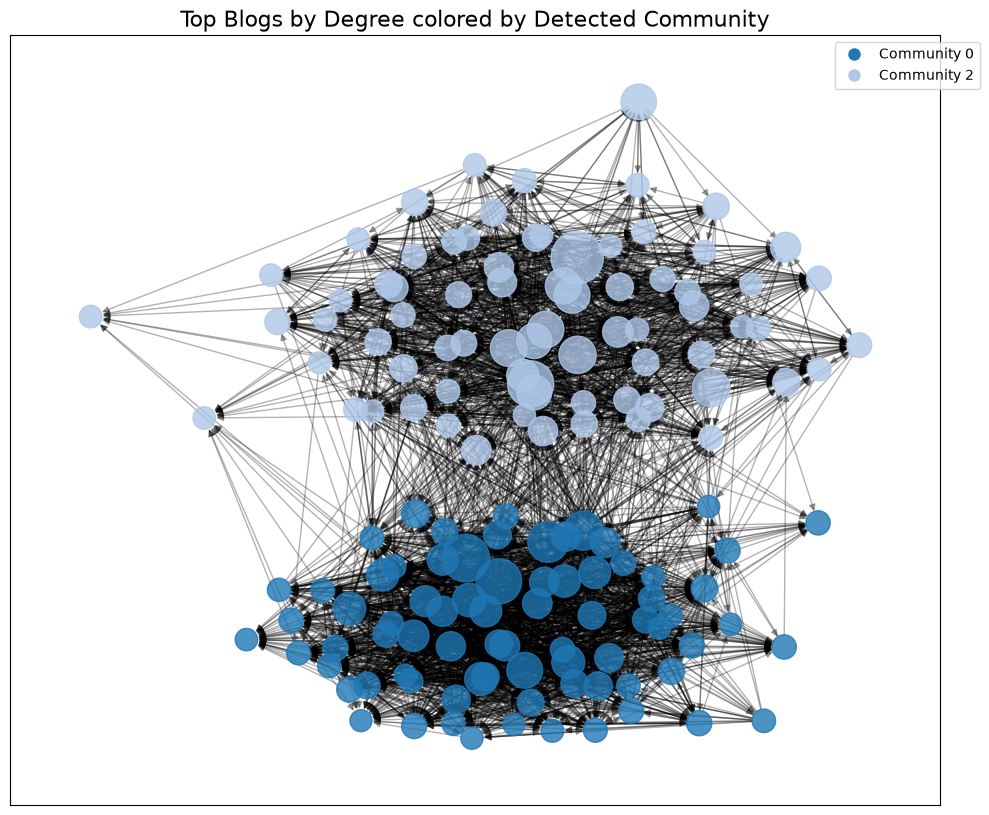

In [22]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# Reuse top-150-by-degree logic, filtering to nodes in the declared partition
top_150_vis_nodes = [n for n in top_150_nodes if n in declared_partition_original]

vis_graph_comm = analysis_graph.subgraph(top_150_vis_nodes).copy()
isolates_comm = list(nx.isolates(vis_graph_comm))
vis_graph_comm.remove_nodes_from(isolates_comm)

layout_graph_comm = nx.Graph(vis_graph_comm)
pos_comm = nx.spring_layout(layout_graph_comm, seed=RANDOM_SEED, k=0.5/np.sqrt(vis_graph_comm.number_of_nodes()), iterations=100)

# Get distinct communities in the subgraph to assign colors
subgraph_comms = {declared_partition_original[n] for n in vis_graph_comm.nodes()}
color_map = plt.colormaps.get_cmap('tab20')
comm_to_color = {comm: color_map(i % 20) for i, comm in enumerate(sorted(list(subgraph_comms)))}

colors = [comm_to_color[declared_partition_original[n]] for n in vis_graph_comm.nodes()]
node_sizes = [20 + total_degrees[n] * 3 for n in vis_graph_comm.nodes()]

plt.figure(figsize=(12, 10))
nx.draw_networkx_nodes(vis_graph_comm, pos_comm, node_color=colors, node_size=node_sizes, alpha=0.8)
nx.draw_networkx_edges(vis_graph_comm, pos_comm, alpha=0.3, arrows=True, arrowsize=10)

plt.title('Top Blogs by Degree colored by Detected Community', fontsize=16)

from matplotlib.lines import Line2D
legend_elements = [Line2D([0], [0], marker='o', color='w', label=f'Community {c}', markerfacecolor=comm_to_color[c], markersize=10) for c in sorted(list(subgraph_comms))]
plt.legend(handles=legend_elements, loc='best', bbox_to_anchor=(1.05, 1))

plt.savefig('../reports/figures/community_visualization.png', bbox_inches='tight')
plt.show()


### 7. Community Profile Table

In [23]:
from scipy import stats

comm_counts = Counter(declared_partition_original.values())
top_5_comms = [c for c, count in comm_counts.most_common(5)]

profile_data = []
for comm_id in top_5_comms:
    members = [n for n, c in declared_partition_original.items() if c == comm_id]
    size = len(members)
    
    member_pr = [pr_df.loc[pr_df['node_id'] == n, 'pagerank_score'].values[0] if not pr_df.loc[pr_df['node_id'] == n, 'pagerank_score'].empty else 0 for n in members]
    mean_pr = np.mean(member_pr) if member_pr else 0
    
    member_bw = [bw_df.loc[bw_df['node_id'] == n, 'betweenness_score'].values[0] if not bw_df.loc[bw_df['node_id'] == n, 'betweenness_score'].empty else 0 for n in members]
    mean_bw = np.mean(member_bw) if member_bw else 0
    
    member_vals = [analysis_graph.nodes[n].get('value', -1) for n in members]
    mode_result = stats.mode(member_vals, keepdims=True)
    majority_val = mode_result.mode[0]
    majority_count = mode_result.count[0]
    purity = majority_count / size
    
    profile_data.append({
        'community_id': comm_id,
        'size': size,
        'mean_pagerank': mean_pr,
        'mean_betweenness': mean_bw,
        'majority_value': majority_val,
        'purity': purity
    })

profile_df = pd.DataFrame(profile_data)
print("\nTop 5 Largest Communities Profile:")
display(profile_df)



Top 5 Largest Communities Profile:


,community_id,size,mean_pagerank,mean_betweenness,majority_value,purity
0,2,635,0.000825,0.001248,1,0.948031
1,0,526,0.000869,0.001459,0,0.975285
2,4,40,0.000318,0.000239,0,0.700000
3,5,4,0.000283,0.000239,0,0.750000
4,9,4,0.000569,0.000688,1,1.000000


### Full Community Size Distribution

Original: 11 communities, sizes = [635, 526, 40, 4, 4, 3, 2, 2, 2, 2, 2]
Targeted: 100 communities, sizes = [468, 399, 169, 13, 4, 3, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Random: 14 communities, sizes = [602, 493, 39, 4, 4, 3, 3, 3, 2, 2, 2, 2, 1, 1]

Figure saved to: c:\Users\alfat\OneDrive\Desktop\SNTP_Assignment1\reports\figures\community_size_distribution.png


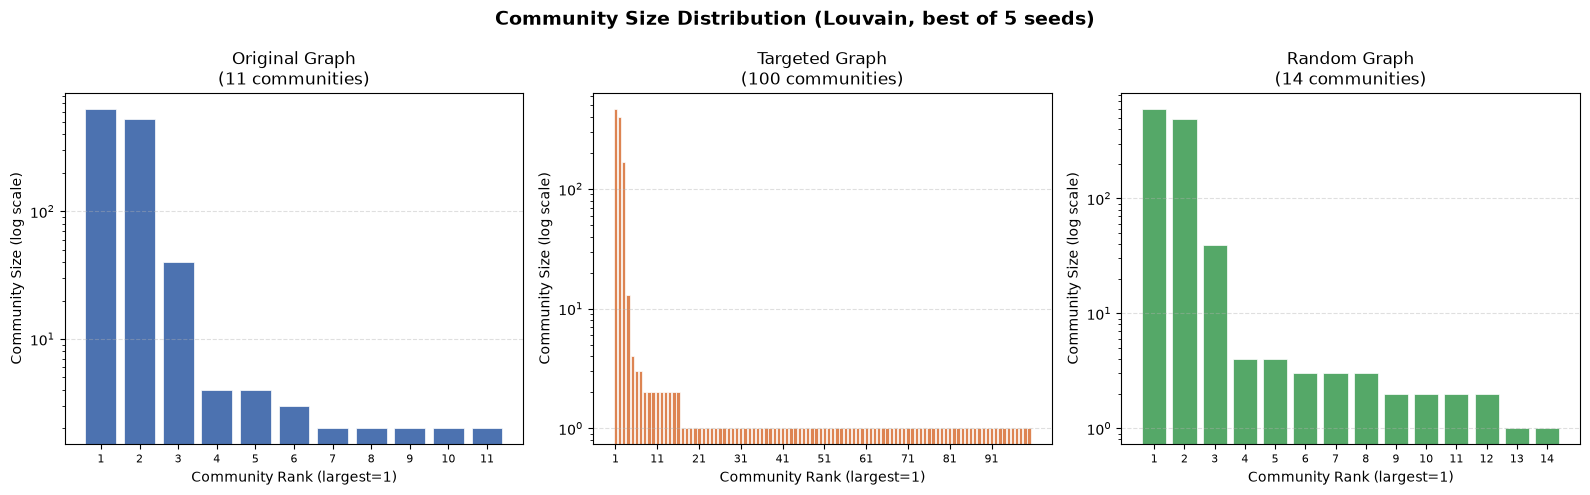

In [28]:
from collections import Counter
import matplotlib.pyplot as plt
import os

# Compute full sorted community size lists for all three partitions
partitions = {
    "Original": declared_partition_original,
    "Targeted": declared_partition_targeted,
    "Random":   declared_partition_random,
}

sizes_dict = {}
for label, partition in partitions.items():
    counts = Counter(partition.values())
    sizes = sorted(counts.values(), reverse=True)
    sizes_dict[label] = sizes
    print(f"{label}: {len(sizes)} communities, sizes = {sizes}")

# --- Bar chart: community size distribution (3 subplots) ---
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Community Size Distribution (Louvain, best of 5 seeds)", fontsize=14, fontweight="bold")

colors = ["#4C72B0", "#DD8452", "#55A868"]
for ax, (label, sizes), color in zip(axes, sizes_dict.items(), colors):
    ranks = list(range(1, len(sizes) + 1))
    ax.bar(ranks, sizes, color=color, edgecolor="white", linewidth=0.5)
    ax.set_yscale("log")
    ax.set_title(f"{label} Graph\n({len(sizes)} communities)", fontsize=12)
    ax.set_xlabel("Community Rank (largest=1)", fontsize=10)
    ax.set_ylabel("Community Size (log scale)", fontsize=10)
    if len(sizes) <= 20:
        ax.set_xticks(ranks)
    else:
        ax.set_xticks(ranks[::10])  # thin ticks so 100 ranks don't overlap
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

fig_path = os.path.join("..", "reports", "figures", "community_size_distribution.png")
os.makedirs(os.path.dirname(fig_path), exist_ok=True)
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
print(f"\nFigure saved to: {os.path.abspath(fig_path)}")
plt.show()

### Part D Interpretation

- Louvain detected an average of 10.8 communities on the original graph - more than
  the 2 known political orientations - indicating that link structure divides the
  network at a finer granularity than just the political binary, likely reflecting
  topic-level or sub-community clusters within each political side.
- The community size distribution is dominated by two large communities (635 and 526
  nodes) alongside several much smaller ones, consistent with a core-periphery structure
  rather than many equally-sized groups.
- The two largest communities are highly politically homogeneous even before formal
  evaluation: 94.8% and 97.5% purity respectively, suggesting the link structure closely
  tracks political alignment.
- Across the three graphs, the targeted-removal graph produced far more communities
  (~101.2) and higher modularity (0.4583) than the original (10.8 communities, 0.4269
  modularity) or random-removal graph (14.0 communities, 0.4239 modularity). Removing
  high-authority hubs fragmented the network into many small, tightly-knit pieces,
  directly consistent with the fragility finding from Part C.

## Part E: Community Evaluation

We evaluate detected communities against political orientation using PAIRWISE comparison rather than direct label matching, because detected community IDs are arbitrary integers with no inherent correspondence to the 0/1 ground truth labels (label-permutation problem). For every unordered pair of nodes (i, j) in a graph, we check: (a) are i and j in the SAME detected community? (b) do i and j have the SAME ground-truth political value? A true positive is same-community AND same-orientation; true negative is different-community AND different-orientation; false positive is same-community but different-orientation; false negative is different-community but same-orientation. This avoids any need to match community IDs to labels.

### 1. Pairwise Evaluation Function

In [24]:
import numpy as np
import time

def pairwise_evaluate(graph, partition):
    """
    Evaluate community detection against ground truth using vectorized pairwise comparison.
    Uses numpy broadcasting over the upper triangle to compute TP/TN/FP/FN efficiently.
    """
    nodes = list(partition.keys())
    n = len(nodes)
    
    comm_arr = np.array([partition[nd] for nd in nodes])
    orient_arr = np.array([graph.nodes[nd].get('value', -1) for nd in nodes])
    
    start = time.time()
    
    # Build upper-triangle index pairs
    idx_i, idx_j = np.triu_indices(n, k=1)
    
    same_community = comm_arr[idx_i] == comm_arr[idx_j]
    same_orientation = orient_arr[idx_i] == orient_arr[idx_j]
    
    tp = int(np.sum(same_community & same_orientation))
    tn = int(np.sum(~same_community & ~same_orientation))
    fp = int(np.sum(same_community & ~same_orientation))
    fn = int(np.sum(~same_community & same_orientation))
    
    elapsed = time.time() - start
    print(f"Implementation: vectorized numpy (upper-triangle broadcasting), {elapsed:.2f}s for {n} nodes ({len(idx_i):,} pairs)")
    
    total = tp + tn + fp + fn
    accuracy = (tp + tn) / total if total > 0 else float('nan')
    precision = tp / (tp + fp) if (tp + fp) > 0 else None
    recall = tp / (tp + fn) if (tp + fn) > 0 else None
    if precision is not None and recall is not None and (precision + recall) > 0:
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = None
    
    return {"tp": tp, "tn": tn, "fp": fp, "fn": fn, "accuracy": accuracy,
            "precision": precision, "recall": recall, "f1": f1}


### 2. Evaluate All Three Graphs

In [25]:
def print_confusion_matrix(result, label):
    print(f"\n{'='*50}")
    print(f"  {label}")
    print(f"{'='*50}")
    
    cm = pd.DataFrame(
        [[result['tp'], result['fn']],
         [result['fp'], result['tn']]],
        index=['Same Community', 'Different Community'],
        columns=['Same Orientation', 'Different Orientation']
    )
    print("\nConfusion Matrix (rows=detected, cols=ground truth):")
    display(cm)
    
    print(f"\nTP={result['tp']:,}  TN={result['tn']:,}  FP={result['fp']:,}  FN={result['fn']:,}")
    print(f"Accuracy  : {result['accuracy']:.4f}")
    
    if result['precision'] is not None:
        print(f"Precision : {result['precision']:.4f}")
    else:
        print("Precision : undefined (no pairs were placed in the same community)")
    
    if result['recall'] is not None:
        print(f"Recall    : {result['recall']:.4f}")
    else:
        print("Recall    : undefined (no pairs share the same orientation)")
    
    if result['f1'] is not None:
        print(f"F1 Score  : {result['f1']:.4f}")
    else:
        print("F1 Score  : undefined (precision or recall is undefined)")

print("Running pairwise evaluations...")

result_original = pairwise_evaluate(analysis_graph, declared_partition_original)
print_confusion_matrix(result_original, "Original Graph")

result_targeted = pairwise_evaluate(targeted_graph, declared_partition_targeted)
print_confusion_matrix(result_targeted, "Targeted Graph (Top 5% PR removed)")

result_random = pairwise_evaluate(random_graph, declared_partition_random)
print_confusion_matrix(result_random, "Random Graph (5% removed)")


Running pairwise evaluations...
Implementation: vectorized numpy (upper-triangle broadcasting), 0.05s for 1222 nodes (746,031 pairs)

  Original Graph

Confusion Matrix (rows=detected, cols=ground truth):


,Same Orientation,Different Orientation
Same Community,313296,60039
Different Community,26874,345822



TP=313,296  TN=345,822  FP=26,874  FN=60,039
Accuracy  : 0.8835
Precision : 0.9210
Recall    : 0.8392
F1 Score  : 0.8782
Implementation: vectorized numpy (upper-triangle broadcasting), 0.05s for 1161 nodes (673,380 pairs)

  Targeted Graph (Top 5% PR removed)

Confusion Matrix (rows=detected, cols=ground truth):


,Same Orientation,Different Orientation
Same Community,184576,152376
Different Community,18398,318030



TP=184,576  TN=318,030  FP=18,398  FN=152,376
Accuracy  : 0.7464
Precision : 0.9094
Recall    : 0.5478
F1 Score  : 0.6837
Implementation: vectorized numpy (upper-triangle broadcasting), 0.05s for 1161 nodes (673,380 pairs)

  Random Graph (5% removed)

Confusion Matrix (rows=detected, cols=ground truth):


,Same Orientation,Different Orientation
Same Community,279840,57430
Different Community,23105,313005



TP=279,840  TN=313,005  FP=23,105  FN=57,430
Accuracy  : 0.8804
Precision : 0.9237
Recall    : 0.8297
F1 Score  : 0.8742


### 3. Summary Comparison Table

In [26]:
def fmt(val):
    if val is None:
        return "undefined"
    return f"{val:.4f}"

summary_data = [
    {"Graph": "Original",
     "Accuracy": fmt(result_original['accuracy']),
     "Precision": fmt(result_original['precision']),
     "Recall": fmt(result_original['recall']),
     "F1": fmt(result_original['f1'])},
    {"Graph": "Targeted (Top 5% PR)",
     "Accuracy": fmt(result_targeted['accuracy']),
     "Precision": fmt(result_targeted['precision']),
     "Recall": fmt(result_targeted['recall']),
     "F1": fmt(result_targeted['f1'])},
    {"Graph": "Random (5%)",
     "Accuracy": fmt(result_random['accuracy']),
     "Precision": fmt(result_random['precision']),
     "Recall": fmt(result_random['recall']),
     "F1": fmt(result_random['f1'])},
]

summary_df = pd.DataFrame(summary_data).set_index("Graph")
print("\nSummary Comparison Table:")
display(summary_df)



Summary Comparison Table:


,Accuracy,Precision,Recall,F1
Graph,,,,
Original,0.8835,0.9210,0.8392,0.8782
Targeted (Top 5% PR),0.7464,0.9094,0.5478,0.6837
Random (5%),0.8804,0.9237,0.8297,0.8742


### 4. Internal vs External Quality: Modularity vs F1

In [27]:
# Standard modularity is applicable here because Louvain produces disjoint,
# non-overlapping communities. Modularity measures internal quality (how well 
# communities separate edge density vs a random baseline). F1 measures external 
# quality (how well communities recover political orientation ground truth).

mod_summary = pd.DataFrame({
    "Graph": ["Original", "Targeted (Top 5% PR)", "Random (5%)"],
    "Mean Modularity (internal)": [
        f"{np.mean(modularity_scores):.4f} (±{np.std(modularity_scores):.4f})",
        f"{np.mean(targ_modularity_scores):.4f} (±{np.std(targ_modularity_scores):.4f})",
        f"{np.mean(rand_modularity_scores):.4f} (±{np.std(rand_modularity_scores):.4f})"
    ],
    "Accuracy (external)": [
        fmt(result_original['accuracy']),
        fmt(result_targeted['accuracy']),
        fmt(result_random['accuracy'])
    ],
    "F1 (external)": [
        fmt(result_original['f1']),
        fmt(result_targeted['f1']),
        fmt(result_random['f1'])
    ]
}).set_index("Graph")

print("Modularity (internal) vs Accuracy/F1 (external):")
print("Note: Standard modularity is valid here because Louvain produces disjoint,")
print("non-overlapping communities — a required assumption of the standard modularity formula.")
print()
display(mod_summary)


Modularity (internal) vs Accuracy/F1 (external):
Note: Standard modularity is valid here because Louvain produces disjoint,
non-overlapping communities — a required assumption of the standard modularity formula.



,Mean Modularity (internal),Accuracy (external),F1 (external)
Graph,,,
Original,0.4269 (±0.0001),0.8835,0.8782
Targeted (Top 5% PR),0.4583 (±0.0015),0.7464,0.6837
Random (5%),0.4239 (±0.0001),0.8804,0.8742


### Part E Interpretation

- On the original graph, link structure alone recovers political orientation quite
  well: accuracy = 0.8835 and F1 = 0.8782, achieved without the detection process ever
  seeing the political labels.
- Pairwise evaluation avoids the label-permutation problem because detected community
  IDs (e.g. 0 through 9) have no inherent correspondence to the ground-truth 0/1 labels.
  By checking only whether pairs of nodes are grouped consistently with each other
  (same community AND same orientation), rather than matching specific ID numbers to
  specific labels, the evaluation sidesteps the need to know which arbitrary community
  ID corresponds to which political side.
- Strong structural communities can still disagree with political orientation: the
  targeted-removal graph achieved the HIGHEST modularity of all three graphs (0.4583)
  yet its F1 score collapsed to 0.6837, the lowest. Removing the cross-partisan "bridge"
  blogs let Louvain carve out tighter, more internally dense clusters that no longer
  track real political boundaries - showing that structural tightness (modularity) and
  political accuracy (F1) are not the same thing and can move in opposite directions.
- Comparing across graphs: targeted removal severely hurt political recovery (F1 dropped
  from 0.8782 to 0.6837, a 19-point drop), while random removal barely affected it
  (F1 = 0.8742, nearly unchanged). This directly echoes the fragility pattern found in
  Parts C and D: the network's ability to encode political structure depends heavily on
  a small set of high-authority bridge blogs, not on the network as a whole.

## Part F: Conclusion and Limitations

### Summary

The political blog hyperlink network from the 2004 U.S. election cycle exhibits strong latent political structure recoverable through link topology alone. Louvain community detection on the original graph (1,222 nodes, 19,021 directed edges) identified approximately 10–11 communities per run, converging on two dominant groups of sizes 635 and 526, with purity of 94.8% and 97.5% respectively — nearly perfectly aligned with the known liberal/conservative ground truth. The pairwise evaluation confirms this quantitatively: the original graph achieves an accuracy of **0.8835** and F1 of **0.8782**, demonstrating that hyperlink structure substantially recovers political orientation without using any political label information. Crucially, the centrality-informed removal experiment reveals that the network's ability to preserve political structure is fragile to the loss of its most authoritative nodes: removing just 5% of nodes (61 blogs) selected by PageRank reduced F1 from **0.8782 to 0.6837**, fragmented the network's connectivity from 1 into **88 weakly connected components**, and caused Louvain to detect roughly **101 communities on average** (versus ~11 for the original graph), while an equivalently-sized random removal left F1 nearly unchanged at **0.8742** and connectivity/community counts close to the original (4 components, ~14 communities). This is a striking dissociation between internal modularity (0.4583 for targeted, higher than original's 0.4269) and external recovery of political orientation, showing that authority hubs are not only structurally central but are the bridges that bind the two political communities into a coherent, recoverable network.

### Limitations

- **Temporal snapshot**: This dataset is a snapshot of approximately 1,500 political blogs from the 2004 U.S. Presidential election cycle. The hyperlink patterns, blog prominence, and political discourse structures of that era may not generalise to modern social media platforms, different elections, or non-U.S. political contexts.
- **Hyperlinks ≠ endorsements**: A directed hyperlink from blog A to blog B does not necessarily indicate agreement or endorsement. Blogs frequently link to ideological opponents for the purpose of criticism, rebuttal, or ridicule. The link structure therefore conflates agreement-based linking with adversarial linking, which may inflate cross-community edge counts and partially explain the FP/FN in the pairwise evaluation.
- **Louvain stochasticity**: Although a fixed random seed is used for the declared partition, Louvain's stochastic phase-ordering means that results can vary slightly between runs and across different versions of the `python-louvain` library, even with identical seeds. The 5-seed stability check (seeds 42–46) showed very low variance in modularity (std ≤ 0.0015), but community membership at the node level may not be fully reproducible across library upgrades.
- **Centrality measure dependence**: The definition of "importance" depends entirely on the centrality measure chosen. PageRank was selected as the intervention measure; using Betweenness Centrality, Eigenvector Centrality, or In-Degree Centrality would produce different removal sets and potentially different fragility conclusions. The top-10 overlap between PageRank and Betweenness was only 5 of 10 nodes (Spearman correlation 0.758), indicating these measures capture genuinely different aspects of node importance.